1. Loading and Preprocessing (4 marks)

● Load the Diabetes dataset from sklearn.

● Handle any missing values if present.

● Normalize the features to ensure better performance of the ANN model.

In [1]:
from sklearn.datasets import load_diabetes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
data = load_diabetes()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(X.head())
print("Dataset shape:", X.shape)

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  
Dataset shape: (442, 10)


In [2]:
X.isna().sum()

,0
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


2. Exploratory Data Analysis (EDA) (4 marks)

● Perform EDA to understand the distribution of features and the target
variable.

● Visualize the relationships between features and the target variable.

In [3]:
X.shape

(442, 10)

In [4]:
X.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


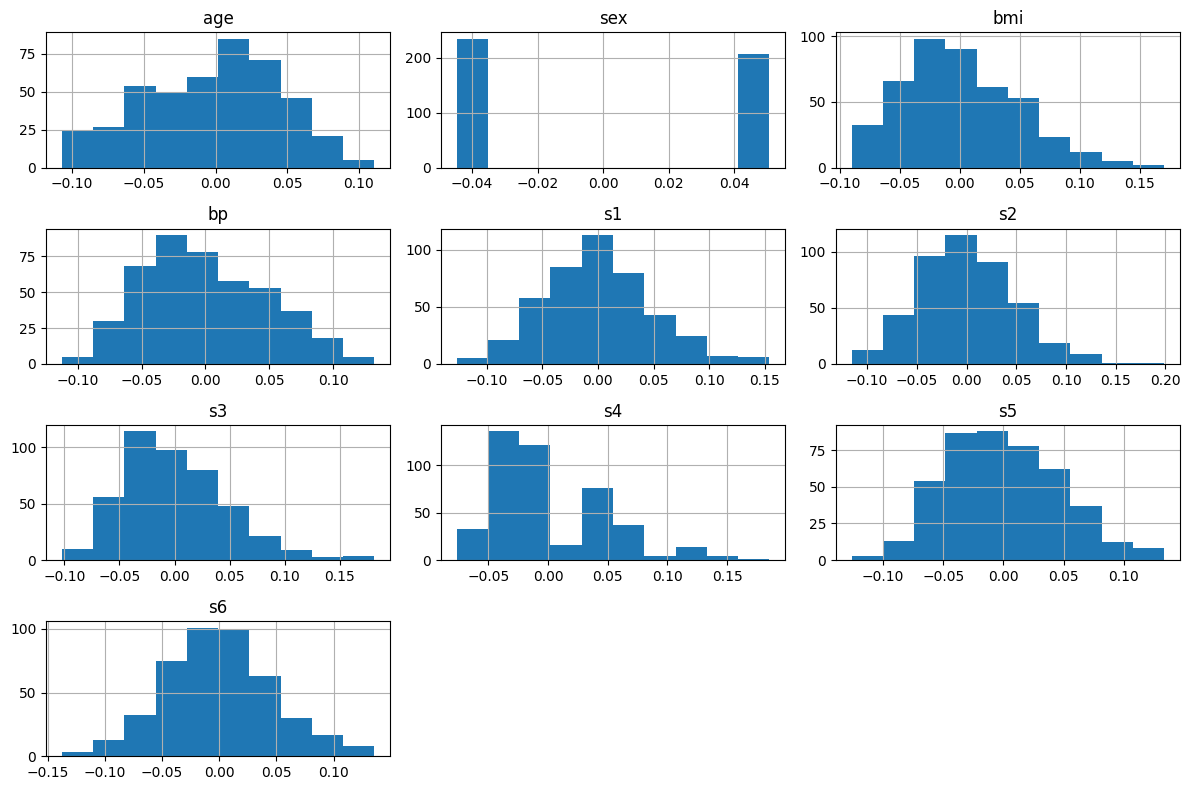

In [5]:
X.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

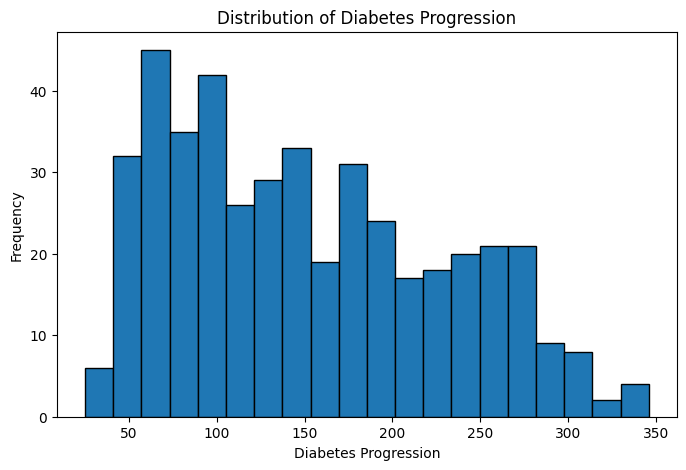

In [6]:
plt.figure(figsize=(8, 5))
plt.hist(y, bins=20, edgecolor="black")

plt.xlabel("Diabetes Progression")
plt.ylabel("Frequency")
plt.title("Distribution of Diabetes Progression")

plt.show()

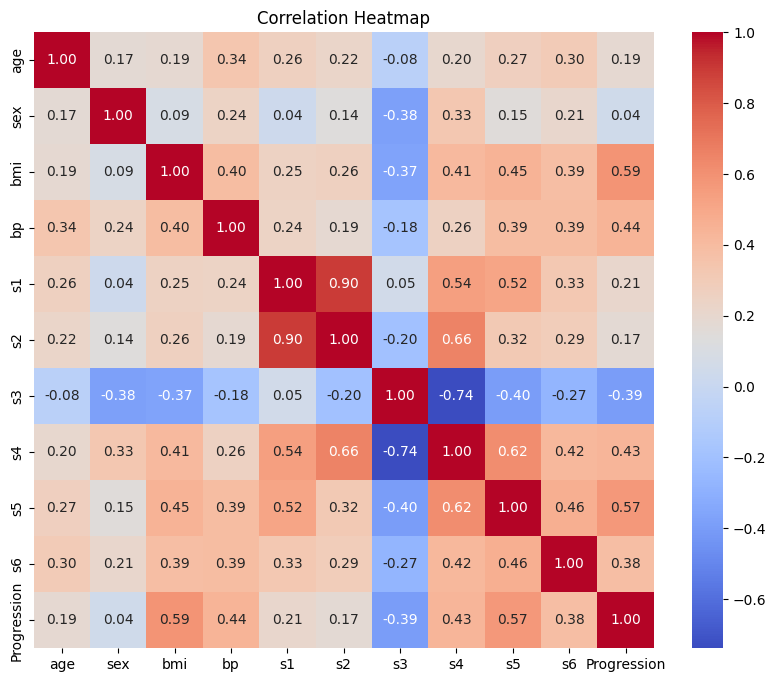

In [7]:
df = X.copy()
df["Progression"] = y

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

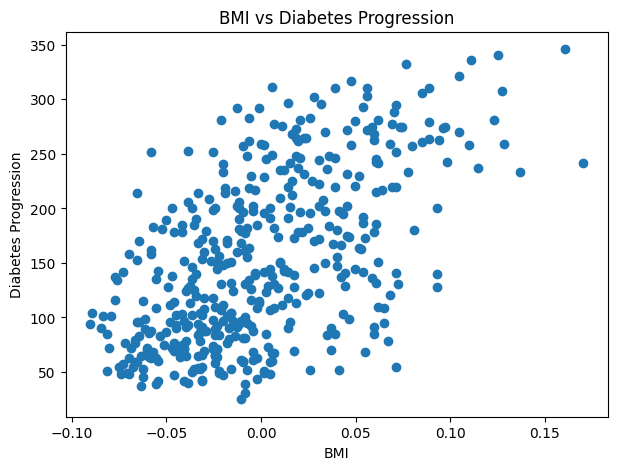

In [8]:
plt.figure(figsize=(7, 5))

plt.scatter(X["bmi"], y)

plt.xlabel("BMI")
plt.ylabel("Diabetes Progression")
plt.title("BMI vs Diabetes Progression")

plt.show()

EDA Conclusion

Exploratory Data Analysis (EDA) was performed to understand the Diabetes dataset, which contains 442 observations and 10 independent variables. The dataset was checked for missing values, and no missing values were found. Statistical summaries and histograms were used to understand the data distributions. A target distribution plot and correlation heatmap were created to examine the target variable and relationships between features. A scatter plot of BMI against diabetes progression showed a generally positive relationship. Overall, EDA helped us understand the dataset before preprocessing and building the ANN model.

3. Building the ANN Model (4 marks)

● Design a simple ANN architecture with at least one hidden layer.

● Use appropriate activation functions .



4. Training the ANN Model (4 marks)

● Split the dataset into training and testing sets.

● Train the model on the training data.

● Use an appropriate loss function and optimizer.

Splitting the dataset

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Normalize features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (353, 10)
Testing data: (89, 10)


Build the ANN model

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential([
    Input(shape=(10,)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="linear")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

Compile and Training the model

In [12]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - loss: 31531.4297 - mae: 158.6574 - val_loss: 22430.0605 - val_mae: 133.8919
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31435.7559 - mae: 158.3657 - val_loss: 22352.3223 - val_mae: 133.6052
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31330.2910 - mae: 158.0426 - val_loss: 22258.2012 - val_mae: 133.2665
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31208.0000 - mae: 157.6672 - val_loss: 22141.5098 - val_mae: 132.8639
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 31051.8730 - mae: 157.2092 - val_loss: 21999.5723 - val_mae: 132.3760
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30854.2168 - mae: 156.6360 - val_loss: 21831.4551 - val_mae: 131.8022
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30605.1426 - mae: 155.9200 - val_loss: 21615.5098 - val_mae: 131.0706
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30289.2227 - mae: 155.0089 - val_loss

5. Evaluating the Model (3 marks)

● Evaluate the model on the testing data.

● Report the performance metrics (e.g., Mean Squared Error, R2 Score).

In [13]:
from sklearn.metrics import mean_squared_error, r2_score

# Predict diabetes progression for test data
y_pred = model.predict(X_test).flatten()

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("R2 Score:", r2)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step
Mean Squared Error (MSE): 3061.22510155916
R2 Score: 0.42220886700418603


The model explains approximately 42.2% of the variation in diabetes progression in the test dataset. MSE = 3061.23: This measures the squared difference between actual and predicted values. Lower is better.

6. Improving the Model (5 marks)

○ Experiment with different architectures, activation functions, or
hyperparameters to improve the model performance.

○ Report the changes made and the corresponding improvement in
performance.

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

improved_model = Sequential([
    Input(shape=(10,)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="linear")
])

improved_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

Compile the improved model

In [15]:
improved_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

Train the improved model

In [16]:
improved_history = improved_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - loss: 31247.7793 - mae: 157.7955 - val_loss: 22189.2363 - val_mae: 132.9999
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31043.1250 - mae: 157.1573 - val_loss: 22010.8730 - val_mae: 132.3426
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30768.3223 - mae: 156.3125 - val_loss: 21772.1523 - val_mae: 131.4609
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 30402.9395 - mae: 155.1731 - val_loss: 21441.3750 - val_mae: 130.2467
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 29883.9473 - mae: 153.6037 - val_loss: 21004.1152 - val_mae: 128.6225
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 29192.6445 - mae: 151.4588 - val_loss: 20401.3398 - val_mae: 126.3774
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 28243.5020 - mae: 148.5194 - val_loss: 19623.6680 - val_mae: 123.4239
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 27000.3340 - mae: 144.6013 - val_loss

Evaluate the improved model

In [17]:
from sklearn.metrics import mean_squared_error, r2_score

# Predict diabetes progression
y_pred_improved = improved_model.predict(X_test).flatten()

# Calculate evaluation metrics
improved_mse = mean_squared_error(y_test, y_pred_improved)
improved_r2 = r2_score(y_test, y_pred_improved)

print("Improved Model MSE:", improved_mse)
print("Improved Model R2 Score:", improved_r2)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 173ms/step
Improved Model MSE: 2851.04366352949
Improved Model R2 Score: 0.46187957633947774


Compare both models

In [18]:
comparison = pd.DataFrame({
    "Model": ["Original ANN", "Improved ANN"],
    "MSE": [mse, improved_mse],
    "R2 Score": [r2, improved_r2]
})

print(comparison)

          Model          MSE  R2 Score
0  Original ANN  3061.225102  0.422209
1  Improved ANN  2851.043664  0.461880


Plot training and validation loss

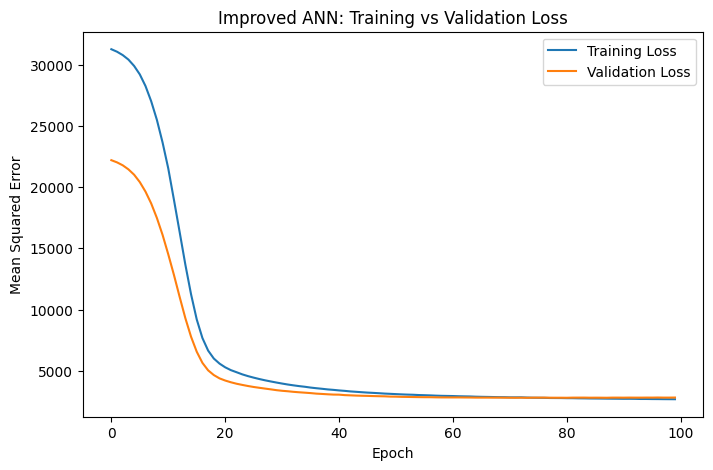

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    improved_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    improved_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Improved ANN: Training vs Validation Loss")
plt.legend()
plt.show()

### Model Improvement and Performance Comparison

The initial ANN model consisted of two hidden layers with 16 and 8 neurons, respectively, using the ReLU activation function. The output layer contained one neuron with a linear activation function. The model achieved a Mean Squared Error (MSE) of **3061.23** and an R² score of **0.4222**.

To improve the model's performance, the number of neurons in the hidden layers was increased from 16 and 8 to 32 and 16, respectively. The optimizer (Adam), loss function (MSE), activation functions, and other training settings were kept the same.

After training the improved model, the MSE decreased to **2851.04**, while the R² score increased to **0.4619**. This represents an approximately **6.9% reduction in MSE** and an improvement in the R² score from 0.4222 to 0.4619.

Overall, increasing the number of neurons in the hidden layers improved the model's predictive performance on the test dataset. However, the model's performance could potentially be improved further by experimenting with other architectures and hyperparameters.